<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# Procesamiento del Lenguaje Natural
## **Desafío 4: Traductor Seq2Seq**

**Integrantes:**
* Rubiolo Pedro Ignacio


---
### **Consigna**

* **Replicar el modelo traductor desarrollado en clase** ([Traductor.ipynb](https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb)) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* **Modificar valores de hiperparámetros** (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* **Analizar el impacto del número de neuronas en las capas recurrentes**, comparando el desempeño de distintas configuraciones del modelo.
* **Generar y presentar al menos cinco ejemplos de traducciones** producidas por el modelo entrenado.
* **Interpretar a detalle los resultados obtenidos**, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### **Actividades opcionales abordadas**
* Incorporar embeddings preentrenados para el idioma de entrada y salida.
* Experimentar con diferentes estrategias de generación de secuencias: **Greedy Search**, **Muestreo Estocástico con Temperatura**, **Beam Search**. 


---
## **1 Imports y configuraciones**

In [1]:
import os
import sys
import json
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model

import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from datasets import load_dataset
# Configuración de estilo visual para gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

# Verificación de aceleración por GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"Dispositivo GPU disponible: {gpus[0].name}")
else:
    print("Ejecutando en CPU.")


I0000 00:00:1791976957.482791    7081 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/nacho/Documents/CEIA/procesamiento_lenguaje_natural/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo GPU disponible: /physical_device:GPU:0


---
## **2. Carga y Análisis Exploratorio de Datos (EDA)**

En la práctica de clase se utilizaron únicamente **10.000 oraciones** con longitudes máximas fijadas arbitrariamente en `max_input_len = 20` y `max_out_len = 22`. 

Para este desafío:
1. **Ampliamos el dataset a 25.000 oraciones** (un incremento del **250%**).
2. Realizamos un análisis empírico de las longitudes de secuencia para determinar longitudes máximas fundamentadas en los percentiles reales del corpus.


In [2]:
spa_candidates = [
    'spa-eng/spa.txt',
    './spa-eng/spa.txt',
    'Desafios/spa-eng/spa.txt',
    './Desafios/spa-eng/spa.txt'
]
spa_path = next((p for p in spa_candidates if os.path.exists(p)), None)
if spa_path is None:
    print("Descargando dataset spa-eng...")
    os.system("curl -L -o spa-eng.zip http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip")
    os.system("unzip -q spa-eng.zip -d Desafios/")
    spa_path = "Desafios/spa-eng/spa.txt"
print(f"Cargando dataset desde: {spa_path}")
with open(spa_path, 'r', encoding='utf-8') as f:
    lines = [line.strip() for line in f if '\t' in line]
print(f"Total de pares en el corpus: {len(lines):,}")
# Seleccionar 25.000 pares mezclados con semilla fija
MAX_NUM_SENTENCES = 25000
np.random.seed(42)
np.random.shuffle(lines)
input_sentences = []
output_sentences = []
output_sentences_inputs = []
for line in lines[:MAX_NUM_SENTENCES]:
    parts = line.split('\t')
    if len(parts) >= 2:
        inp, out = parts[0], parts[1]
        input_sentences.append(inp)
        output_sentences.append(out + ' <eos>')
        output_sentences_inputs.append('<sos> ' + out)
print(f"Oraciones seleccionadas: {len(input_sentences):,}")
print("Ejemplo 0:")
print(f"  EN:      {input_sentences[0]}")
print(f"  ES (out): {output_sentences[0]}")
print(f"  ES (in):  {output_sentences_inputs[0]}")


Cargando dataset desde: spa-eng/spa.txt
Total de pares en el corpus: 118,964
Oraciones seleccionadas: 25,000
Ejemplo 0:
  EN:      How boring!
  ES (out): ¡Qué aburrimiento! <eos>
  ES (in):  <sos> ¡Qué aburrimiento!


,Percentil,Longitud Inglés (palabras),Longitud Español (palabras)
0,p50,6.0,7.0
1,p75,8.0,8.0
2,p90,10.0,11.0
3,p95,11.0,12.0
4,p99,14.0,16.0
5,p100,47.0,50.0


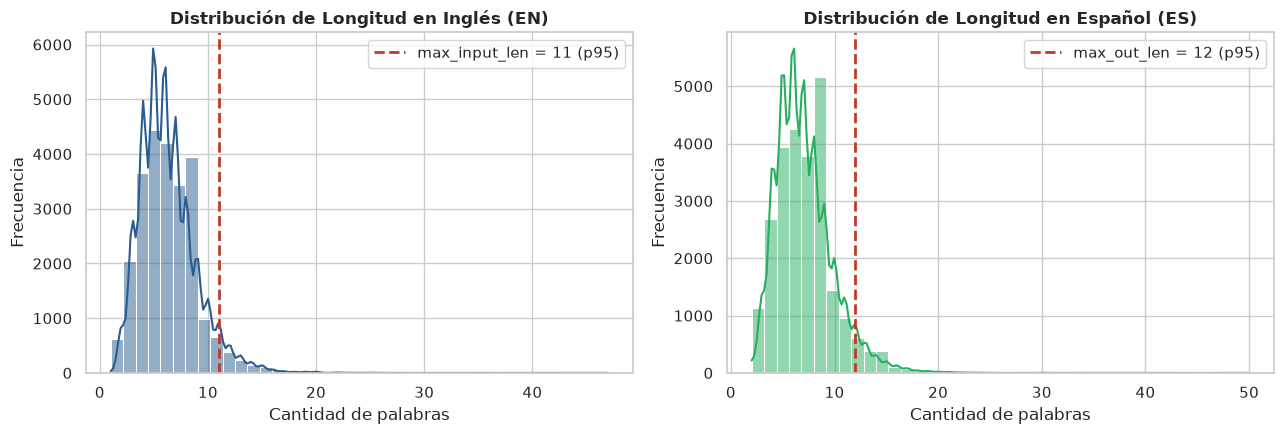

In [3]:
# Análisis cuantitativo de longitudes
en_lengths = [len(s.split()) for s in input_sentences]
es_lengths = [len(s.split()) for s in output_sentences]

pcts = [50, 75, 90, 95, 99, 100]
df_lengths = pd.DataFrame({
    'Percentil': [f"p{p}" for p in pcts],
    'Longitud Inglés (palabras)': np.percentile(en_lengths, pcts),
    'Longitud Español (palabras)': np.percentile(es_lengths, pcts)
})
display(df_lengths)

# Corte dinámico (ejemplo: percentil 95 o 98)
CUTOFF_PCT = 95
cutoff_en = int(np.percentile(en_lengths, CUTOFF_PCT))
cutoff_es = int(np.percentile(es_lengths, CUTOFF_PCT))

# Visualización gráfica consistente
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(en_lengths, bins=40, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].axvline(cutoff_en, color='#c0392b', linestyle='--', linewidth=2, 
                label=f'max_input_len = {cutoff_en} (p{CUTOFF_PCT})')
axes[0].set_title('Distribución de Longitud en Inglés (EN)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Cantidad de palabras')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

sns.histplot(es_lengths, bins=40, kde=True, ax=axes[1], color='#27ae60')
axes[1].axvline(cutoff_es, color='#c0392b', linestyle='--', linewidth=2, 
                label=f'max_out_len = {cutoff_es} (p{CUTOFF_PCT})')
axes[1].set_title('Distribución de Longitud en Español (ES)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cantidad de palabras')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()

plt.tight_layout()
plt.show()


En este caso seleccionamos el perecentil 95 para definir la longitdud de las secuencias para ambos idiomas.

---
## **3. Tokenización, Vocabulario Expandido y Pipeline `tf.data.Dataset`**

* **Tamaño del Vocabulario:** Ampliamos el vocabulario a `MAX_VOCAB_SIZE = 10,000` palabras (frente a 8.000 en clase).
* **Estrategia de Padding:**
  * **Encoder (`pre-padding`):** El padding se aplica al inicio (`padding='pre'`). De este modo, los últimos pasos temporales que procesa la LSTM del Encoder contienen las palabras reales de la oración en lugar de ceros, asegurando que el context vector conserve la máxima densidad de información semántica sin desvanecimiento por ceros.
  * **Decoder (`post-padding`):** El padding se coloca al final (`padding='post'`). El decoder comienza inmediatamente con el token `<sos>` y los tokens válidos, acumulando los ceros residuales al final.


In [4]:
MAX_VOCAB_SIZE = 10000
max_input_len = cutoff_en
max_out_len   = cutoff_es


# Tokenizador de entrada (Inglés)
FILTROS_LITERARIOS = '!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n–—«»“”‘’¿¡'
input_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    filters=FILTROS_LITERARIOS + '<>'
)
input_tokenizer.fit_on_texts(input_sentences)
input_integer_seq = input_tokenizer.texts_to_sequences(input_sentences)
word2idx_inputs = input_tokenizer.word_index

# Tokenizador de salida (Español)
output_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    filters=FILTROS_LITERARIOS
)
output_tokenizer.fit_on_texts(["<sos>", "<eos>"] + output_sentences)
output_integer_seq = output_tokenizer.texts_to_sequences(output_sentences)
output_input_integer_seq = output_tokenizer.texts_to_sequences(output_sentences_inputs)
word2idx_outputs = output_tokenizer.word_index

idx2word_inputs  = {v: k for k, v in word2idx_inputs.items()}
idx2word_outputs = {v: k for k, v in word2idx_outputs.items()}

num_words_output = min(len(word2idx_outputs) + 1, MAX_VOCAB_SIZE)
nb_words_input   = min(len(word2idx_inputs) + 1, MAX_VOCAB_SIZE)

print(f"Vocabulario total EN: {len(word2idx_inputs):,} palabras | Utilizadas: {nb_words_input:,}")
print(f"Vocabulario total ES: {len(word2idx_outputs):,} palabras | Utilizadas: {num_words_output:,}")
print(f"Longitudes fijadas: max_input_len = {max_input_len}, max_out_len = {max_out_len}")

# Padding de secuencias
encoder_input_sequences  = pad_sequences(input_integer_seq,        maxlen=max_input_len, padding='pre')
decoder_input_sequences  = pad_sequences(output_input_integer_seq, maxlen=max_out_len,   padding='post')
decoder_output_sequences = pad_sequences(output_integer_seq,       maxlen=max_out_len,   padding='post')

# Partición en entrenamiento (85%) y validación/test (15%)
BATCH_SIZE = 64
val_split  = 0.15
split_idx  = int(len(encoder_input_sequences) * (1 - val_split))

train_enc     = encoder_input_sequences[:split_idx]
train_dec_in  = decoder_input_sequences[:split_idx]
train_dec_out = decoder_output_sequences[:split_idx]

val_enc     = encoder_input_sequences[split_idx:]
val_dec_in  = decoder_input_sequences[split_idx:]
val_dec_out = decoder_output_sequences[split_idx:]

val_raw_inputs  = input_sentences[split_idx:]
val_raw_outputs = output_sentences[split_idx:]

print(f"Muestras de entrenamiento: {len(train_enc):,} | Muestras de validación: {len(val_enc):,}")

def make_dataset(enc_seqs, dec_in_seqs, dec_out_seqs, batch_size, num_classes):
    n = len(enc_seqs)
    def generator():
        for i in range(n):
            yield (
                enc_seqs[i].astype(np.int32),
                dec_in_seqs[i].astype(np.int32),
                dec_out_seqs[i].astype(np.int32)
            )

    def encode_one_hot(enc, dec_in, dec_out):
        y = tf.one_hot(dec_out, depth=num_classes)
        return (enc, dec_in), y

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(max_input_len,), dtype=tf.int32),
            tf.TensorSpec(shape=(max_out_len,),   dtype=tf.int32),
            tf.TensorSpec(shape=(max_out_len,),   dtype=tf.int32)
        )
    )
    ds = ds.map(encode_one_hot, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_enc, train_dec_in, train_dec_out, BATCH_SIZE, num_words_output)
val_ds   = make_dataset(val_enc,   val_dec_in,   val_dec_out,   BATCH_SIZE, num_words_output)


Vocabulario total EN: 7,535 palabras | Utilizadas: 7,536
Vocabulario total ES: 12,552 palabras | Utilizadas: 10,000
Longitudes fijadas: max_input_len = 11, max_out_len = 12
Muestras de entrenamiento: 21,250 | Muestras de validación: 3,750


I0000 00:00:1791976973.537269    7081 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2579 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5


---
## **4. Incorporación de Embeddings Preentrenados (GloVe)**

Para acelerar la convergencia y enriquecer la representación del inglés, incorporamos vectores **GloVe** de 50 dimensiones entrenados sobre Wikipedia y Gigaword (1.19 millones de términos).

La matriz de pesos se inicializa con estos vectores y se congela (`trainable=False`), preservando la semántica preentrenada.


In [5]:
EMBED_DIM = 50
glove_candidates = [
    'gloveembedding.pkl',
    './gloveembedding.pkl',
    'Desafios/gloveembedding.pkl',
    '../Desafios/gloveembedding.pkl'
]
glove_path = next((p for p in glove_candidates if os.path.exists(p)), 'gloveembedding.pkl')

print(f"Cargando embeddings GloVe desde {glove_path}...")
max_bytes = 2**28 - 1
raw = bytearray()
sz  = os.path.getsize(glove_path)
with open(glove_path, 'rb') as f:
    for _ in range(0, sz, max_bytes):
        raw += f.read(max_bytes)

glove_data     = pickle.loads(raw)
glove_word2idx = dict(zip(glove_data['word'], np.arange(glove_data.shape[0])))

def get_word_embedding(word, embeddings, word2idx, n_features=50):
    i = word2idx.get(word, -1)
    return embeddings[i]['embedding'] if i != -1 else np.zeros(n_features)

def build_embedding_matrix(word2idx_inputs, embeddings, word2idx_glove, nb_words, embed_dim=50):
    matrix = np.zeros((nb_words, embed_dim))
    for word, i in word2idx_inputs.items():
        if i < nb_words:
            vec = get_word_embedding(word, embeddings, word2idx_glove, embed_dim)
            if vec is not None and len(vec) > 0:
                matrix[i] = vec
    return matrix

embedding_matrix = build_embedding_matrix(
    word2idx_inputs, glove_data, glove_word2idx, nb_words_input, EMBED_DIM
)

zeros_cnt = np.sum(np.sum(embedding_matrix**2, axis=1) == 0)
print(f"Matriz de embeddings construida: shape = {embedding_matrix.shape}")
print(f"Palabras cubiertas en GloVe: {nb_words_input - zeros_cnt:,} ({(nb_words_input - zeros_cnt)/nb_words_input*100:.2f}%)")
print(f"Palabras fuera de vocabulario (OOV / ceros): {zeros_cnt:,}")

del glove_data, raw


Cargando embeddings GloVe desde gloveembedding.pkl...
Matriz de embeddings construida: shape = (7536, 50)
Palabras cubiertas en GloVe: 7,194 (95.46%)
Palabras fuera de vocabulario (OOV / ceros): 342


Se realizó tambien sobre el decoder. Incorporamos vectores **GloVe** de 300 dimensiones entrenados sobre Spanish Billion Words Corpus.

La matriz de pesos se inicializa con estos vectores y a diferencia del encoder. no se congela (`trainable=True`), para mejorar la representacion de los tokens especiales que no se encuentran en el modelo preentrenado.

In [6]:
EMBED_DIM_ES = 300
glove_es_path = 'glove-sbwc.i25.vec'

print(f"Cargando embeddings GloVe para español desde {glove_es_path}...")

es_embeddings_index = {}
vocab_es_set = set(word2idx_outputs.keys())

with open(glove_es_path, 'r', encoding='utf-8', errors='ignore') as f:
    for line in f:
        values = line.rstrip().split(' ')
        word = values[0]
        if word in vocab_es_set:
            vector = np.asarray(values[1:], dtype='float32')
            if len(vector) == EMBED_DIM_ES:
                es_embeddings_index[word] = vector

print(f"Palabras encontradas en el embedding: {len(es_embeddings_index):,}")

embedding_matrix_es = np.zeros((num_words_output, EMBED_DIM_ES), dtype='float32')

for word, idx in word2idx_outputs.items():
    if idx < num_words_output:
        if word in es_embeddings_index:
            embedding_matrix_es[idx] = es_embeddings_index[word]
        elif word in ['<sos>', '<eos>']:
            # Inicialización aleatoria pequeña para tokens especiales
            embedding_matrix_es[idx] = np.random.normal(scale=0.05, size=EMBED_DIM_ES)
        else:
            # Palabras fuera de vocabulario (OOV)
            embedding_matrix_es[idx] = np.random.normal(scale=0.01, size=EMBED_DIM_ES)

print(f"Matriz Decoder construida con forma: {embedding_matrix_es.shape}")




Cargando embeddings GloVe para español desde glove-sbwc.i25.vec...
Palabras encontradas en el embedding: 12,146
Matriz Decoder construida con forma: (10000, 300)


---
## **5. Construcción Modular del Modelo Seq2Seq y Modelos de Inferencia**

Definimos una `build_seq2seq_model` que genera:
1. **Modelo de Entrenamiento:** Acopla Encoder y Decoder con *Teacher Forcing*.
2. **Modelo de Encoder para Inferencia:** Recibe la secuencia fuente y devuelve únicamente los estados finales $[h, c]$.
3. **Modelo de Decoder para Inferencia:** Recibe un único token y los estados previos $[h, c]$, retornando la distribución de probabilidades del siguiente token y los nuevos estados actualizados.


In [7]:
def build_seq2seq_model(
    n_units, 
    nb_words_in, 
    embed_dim_in, 
    emb_matrix_in, 
    num_words_out, 
    embed_dim_out,
    emb_matrix_out,
    max_in_len, 
    max_out_len
):
    # --- ENCODER (GloVe Inglés) ---
    enc_inputs = Input(shape=(max_in_len,), name='encoder_inputs')
    enc_emb_layer = Embedding(
        input_dim=nb_words_in,
        output_dim=embed_dim_in,
        weights=[emb_matrix_in],
        trainable=False,  # Congelado
        name='encoder_embedding'
    )
    enc_emb = Dropout(0.3, name='encoder_dropout')(enc_emb_layer(enc_inputs))
    enc_lstm_layer = LSTM(n_units, return_state=True, name='encoder_lstm')
    _, state_h, state_c = enc_lstm_layer(enc_emb)
    enc_states = [state_h, state_c]

    # --- DECODER (GloVe Español) ---
    dec_inputs = Input(shape=(max_out_len,), name='decoder_inputs')
    dec_emb_layer = Embedding(
        input_dim=num_words_out,
        output_dim=embed_dim_out,         # 300
        weights=[emb_matrix_out],         # Pesos preentrenados
        trainable=True,                   # RECOMENDADO: trainable=True en el Decoder
        name='decoder_embedding'
    )
    dec_emb = Dropout(0.3, name='decoder_dropout')(dec_emb_layer(dec_inputs))
    
    dec_lstm_layer = LSTM(n_units, return_sequences=True, return_state=True, name='decoder_lstm')
    dec_out, _, _ = dec_lstm_layer(dec_emb, initial_state=enc_states)
    
    dec_dense_layer = Dense(num_words_out, activation='softmax', name='decoder_dense')
    dec_outputs = dec_dense_layer(dec_out)

    train_model = Model([enc_inputs, dec_inputs], dec_outputs, name=f'seq2seq_{n_units}u')

    # --- INFERENCIA: ENCODER ---
    enc_inf_model = Model(enc_inputs, enc_states, name=f'encoder_inf_{n_units}u')

    # --- INFERENCIA: DECODER PASO A PASO ---
    dec_single_in = Input(shape=(1,), name='dec_input_single')
    dec_sh_in     = Input(shape=(n_units,), name='dec_state_h_in')
    dec_sc_in     = Input(shape=(n_units,), name='dec_state_c_in')

    dec_single_emb = dec_emb_layer(dec_single_in)
    dec_single_out, dec_sh_out, dec_sc_out = dec_lstm_layer(
        dec_single_emb, initial_state=[dec_sh_in, dec_sc_in]
    )
    dec_single_preds = dec_dense_layer(dec_single_out)

    dec_inf_model = Model(
        [dec_single_in, dec_sh_in, dec_sc_in],
        [dec_single_preds, dec_sh_out, dec_sc_out],
        name=f'decoder_inf_{n_units}u'
    )

    return train_model, enc_inf_model, dec_inf_model


---
## **6. Estrategias de Generación de Secuencias**

Implementamos y comparamos tres estrategias de decodificación:

1. **Greedy Search:**
   Selecciona en cada paso temporal el token con máxima probabilidad
   

2. **Stochastic Sampling con Temperatura:**
   Aplica una escala térmica a los logits antes de la función softmax
   

3. **Beam Search:**
   Mantiene activas las mejores $K$ hipótesis simultáneamente, acumulando las log-probabilidades normalizadas por longitud para evitar sesgo hacia secuencias cortas
   


In [8]:
def translate_greedy(input_seq, enc_inf, dec_inf, max_out_len=27):
    """Generación determinística greedy (argmax)."""
    h, c = enc_inf.predict(input_seq, verbose=0)
    target_seq = np.zeros((1, 1), dtype=np.int32)
    target_seq[0, 0] = word2idx_outputs['<sos>']
    eos = word2idx_outputs['<eos>']

    output_words = []
    for _ in range(max_out_len):
        tokens, h, c = dec_inf.predict([target_seq, h, c], verbose=0)
        idx = int(np.argmax(tokens[0, 0, :]))
        if idx == eos:
            break
        if idx > 0 and idx in idx2word_outputs:
            output_words.append(idx2word_outputs[idx])
        target_seq[0, 0] = idx
    return ' '.join(output_words)

def translate_sampling(input_seq, enc_inf, dec_inf, temperature=0.7, max_out_len=27):
    """Generación estocástica con muestreo controlado por temperatura."""
    h, c = enc_inf.predict(input_seq, verbose=0)
    target_seq = np.zeros((1, 1), dtype=np.int32)
    target_seq[0, 0] = word2idx_outputs['<sos>']
    eos = word2idx_outputs['<eos>']

    output_words = []
    for _ in range(max_out_len):
        tokens, h, c = dec_inf.predict([target_seq, h, c], verbose=0)
        probs = tokens[0, 0, :].astype('float64')
        probs = np.log(np.maximum(probs, 1e-12)) / temperature
        exp_p = np.exp(probs - np.max(probs))
        p     = exp_p / np.sum(exp_p)
        idx   = int(np.random.choice(len(p), p=p))
        if idx == eos:
            break
        if idx > 0 and idx in idx2word_outputs:
            output_words.append(idx2word_outputs[idx])
        target_seq[0, 0] = idx
    return ' '.join(output_words)

def translate_beam_search(input_seq, enc_inf, dec_inf, beam_width=3, length_penalty=0.7, max_out_len=27):
    """Búsqueda por haz (Beam Search) con penalización por longitud."""
    h, c = enc_inf.predict(input_seq, verbose=0)
    sos  = word2idx_outputs['<sos>']
    eos  = word2idx_outputs['<eos>']

    beams = [(0.0, [sos], h, c)]
    completed = []

    for _ in range(max_out_len):
        candidates = []
        for score, seq, b_h, b_c in beams:
            if seq[-1] == eos:
                completed.append((score / (len(seq) ** length_penalty), seq))
                continue
            t_seq = np.array([[seq[-1]]], dtype=np.int32)
            tokens, next_h, next_c = dec_inf.predict([t_seq, b_h, b_c], verbose=0)
            probs = tokens[0, 0, :]
            top_k = np.argsort(probs)[-beam_width:]
            for idx in top_k:
                log_p = float(np.log(max(probs[idx], 1e-12)))
                candidates.append((score + log_p, seq + [int(idx)], next_h, next_c))

        if not candidates:
            break
        candidates.sort(key=lambda x: x[0], reverse=True)
        beams = candidates[:beam_width]
        if all(seq[-1] == eos for _, seq, _, _ in beams):
            for score, seq, _, _ in beams:
                completed.append((score / (len(seq) ** length_penalty), seq))
            break

    if not completed:
        for score, seq, _, _ in beams:
            completed.append((score / (len(seq) ** length_penalty), seq))

    best_score, best_seq = max(completed, key=lambda x: x[0])
    res_words = [idx2word_outputs[i] for i in best_seq if i not in (sos, eos) and i in idx2word_outputs]
    return ' '.join(res_words)

def translate(text, enc_inf, dec_inf, strategy='greedy', **kwargs):
    """Función de traducción unificada."""
    seq = input_tokenizer.texts_to_sequences([text])
    seq = pad_sequences(seq, maxlen=max_input_len, padding='pre')
    if strategy == 'greedy':
        return translate_greedy(seq, enc_inf, dec_inf, **kwargs)
    elif strategy == 'sampling':
        return translate_sampling(seq, enc_inf, dec_inf, **kwargs)
    elif strategy == 'beam':
        return translate_beam_search(seq, enc_inf, dec_inf, **kwargs)
    else:
        raise ValueError(f"Estrategia desconocida: {strategy}")


---
## **7. Experimentación: Impacto del Número de Unidades Recurrentes (LSTM)**

Para evaluar el impacto de la capacidad del modelo en la calidad de la traducción, definimos y comparamos tres configuraciones:

* **Configuración 1 (Compacta): $N = 128$ unidades LSTM.** Arquitectura ligera, bajo requerimiento de parámetros, menor riesgo de sobreajuste pero potencial cuello de botella severo.
* **Configuración 2 (Media / Base de Clase): $N = 256$ unidades LSTM.** La configuración de referencia empleada en clase, escalada al dataset de 25.000 oraciones.
* **Configuración 3 (Alta Capacidad): $N = 512$ unidades LSTM.** Espacio latente de mayor dimensión ($h \in \mathbb{R}^{512}, c \in \mathbb{R}^{512}$), capaz de capturar relaciones semánticas más complejas y dependencias más largas.


In [9]:
configs = [128, 256, 512]
models_dict = {}
histories = {} 

for units in configs:
    model_path = f"model_lstm_{units}.keras"
    if not os.path.exists(model_path) and os.path.exists(f"Desafios/{model_path}"):
        model_path = f"Desafios/{model_path}"

    train_m, enc_m, dec_m = build_seq2seq_model(
        n_units=units,
        nb_words_in=nb_words_input,
        embed_dim_in=EMBED_DIM,
        emb_matrix_in=embedding_matrix,
        num_words_out=num_words_output,
        embed_dim_out=EMBED_DIM_ES,
        emb_matrix_out=embedding_matrix_es, 
        max_in_len=max_input_len,
        max_out_len=max_out_len
    )


    if os.path.exists(model_path):
        print(f"Cargando pesos preentrenados para {units} unidades desde: {model_path}")
        train_m.load_weights(model_path)
    else:
        print(f"Entrenando modelo de {units} unidades...")
        train_m.compile(
            loss='categorical_crossentropy',
            optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
            metrics=['accuracy']
        )
        lr_sched = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)
        early_st = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1)
        hist = train_m.fit(train_ds, validation_data=val_ds, epochs=18, callbacks=[lr_sched, early_st])
        train_m.save(model_path)
        
        histories[units] = hist.history

    models_dict[units] = {'train': train_m, 'encoder': enc_m, 'decoder': dec_m}

print("\nArquitecturas cargadas y listas para inferencia y evaluación.")
if histories:
    with open('desafio4_experiment_results.json', 'w', encoding='utf-8') as f:
        results_to_save = {
            str(u): {'units': u, 'history': h} 
            for u, h in histories.items()
        }
        json.dump(results_to_save, f, indent=2)
    print("Nuevo archivo desafio4_experiment_results.json guardado con éxito.")


Cargando pesos preentrenados para 128 unidades desde: model_lstm_128.keras
Cargando pesos preentrenados para 256 unidades desde: model_lstm_256.keras
Cargando pesos preentrenados para 512 unidades desde: model_lstm_512.keras

Arquitecturas cargadas y listas para inferencia y evaluación.


Loaded results from: desafio4_experiment_results.json


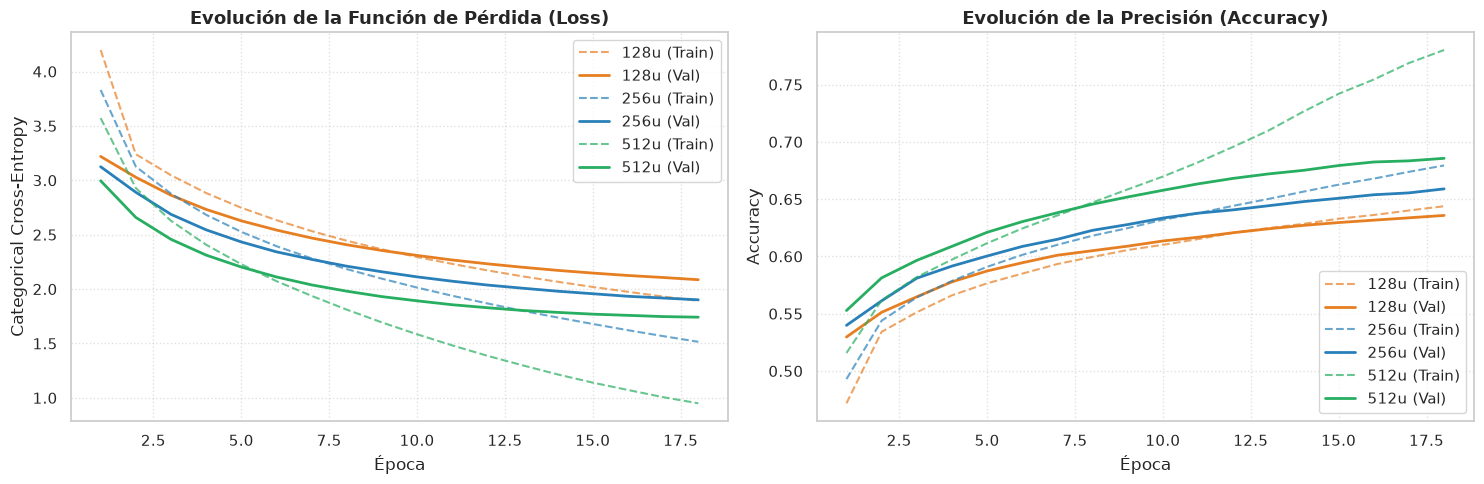

In [10]:
json_candidates = [
    'desafio4_experiment_results.json',
    'Desafios/desafio4_experiment_results.json',
    './desafio4_experiment_results.json'
]
json_path = next((p for p in json_candidates if os.path.exists(p)), None)
if json_path is None:
    raise FileNotFoundError("desafio4_experiment_results.json not found!")
with open(json_path, 'r', encoding='utf-8') as f:
    results = json.load(f)
print(f"Loaded results from: {json_path}")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
palette = {128: '#e67e22', 256: '#2980b9', 512: '#27ae60'}
for u in [128, 256, 512]:
    h = results[str(u)]['history']
    ep = range(1, len(h['loss']) + 1)
    
    axes[0].plot(ep, h['loss'], linestyle='--', color=palette[u], alpha=0.7, label=f'{u}u (Train)')
    axes[0].plot(ep, h['val_loss'], linestyle='-', linewidth=2, color=palette[u], label=f'{u}u (Val)')
    axes[1].plot(ep, h['accuracy'], linestyle='--', color=palette[u], alpha=0.7, label=f'{u}u (Train)')
    axes[1].plot(ep, h['val_accuracy'], linestyle='-', linewidth=2, color=palette[u], label=f'{u}u (Val)')
axes[0].set_title('Evolución de la Función de Pérdida (Loss)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Categorical Cross-Entropy')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right')
axes[1].set_title('Evolución de la Precisión (Accuracy)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()


---
## **8. Ejemplos de Traducción y Comparación Cualitativa**

A continuación presentamos **10 ejemplos de oraciones extraídas del conjunto de prueba/validación**, comparando la referencia real (*Ground Truth*) frente a las hipótesis generadas por cada uno de los tres modelos entrenados.


In [14]:
test_samples_comparison = []
import random

for _ in range(5):
    i = random.randint(0,len(val_raw_inputs))
    en_txt = val_raw_inputs[i]
    gt_txt = val_raw_outputs[i].replace(' <eos>', '').replace('<sos> ', '')
    
    p128 = translate(en_txt, models_dict[128]['encoder'], models_dict[128]['decoder'], strategy='greedy')
    p256 = translate(en_txt, models_dict[256]['encoder'], models_dict[256]['decoder'], strategy='greedy')
    p512 = translate(en_txt, models_dict[512]['encoder'], models_dict[512]['decoder'], strategy='greedy')
    
    test_samples_comparison.append({
        '#': i + 1,
        'Entrada Inglés (EN)': en_txt,
        'Referencia Real (ES)': gt_txt,
        'Modelo 128u': p128,
        'Modelo 256u': p256,
        'Modelo 512u': p512
    })

df_test_comparison = pd.DataFrame(test_samples_comparison)
display(df_test_comparison)

,#,Entrada Inglés (EN),Referencia Real (ES),Modelo 128u,Modelo 256u,Modelo 512u
0,2545,I had to do it.,Tuve que hacerlo.,me gusta hacer eso,tuve que hacer,tuve que hacer eso
1,778,Did you do it by yourself?,¿Lo hiciste tú solo?,sabes que te gusta la,te gustaría hacer eso,te gustaría hacer eso
2,2272,I'm an adult now.,Ahora soy adulto.,es un poco de la semana,es un buen trabajo,es un buen restaurante
3,2558,Do you miss me?,¿Me echas de menos?,te gusta mi,me gusta,me amas
4,3057,I'd rather walk.,Preferiría caminar.,no hay nada,no se movió,no se movió


---
## **9. Pruebas con Frases Nuevas y Comparativa de Estrategias de Decodificación**

Sometemos al mejor modelo (**512 unidades**) a oraciones novedosas no vistas en el dataset, de diversa longitud y complejidad estructural, contrastando las tres técnicas de decodificación:
* **Greedy Search**
* **Beam Search ($k=3$)**
* **Stochastic Sampling ($T=0.7$)**


In [13]:
novel_phrases = [
    "Where is the train station?",
    "I love learning foreign languages.",
    "Can you help me with this task?",
    "She works as a software engineer.",
    "We should go for a walk in the park today.",
    "The food was delicious and the service was great."
]

enc_512 = models_dict[512]['encoder']
dec_512 = models_dict[512]['decoder']

novel_rows = []
for s in novel_phrases:
    novel_rows.append({
        'Frase Novedosa (EN)': s,
        'Greedy Search': translate(s, enc_512, dec_512, strategy='greedy'),
        'Beam Search (k=3)': translate(s, enc_512, dec_512, strategy='beam', beam_width=3),
        'Sampling (T=0.7)': translate(s, enc_512, dec_512, strategy='sampling', temperature=0.7)
    })

df_novel = pd.DataFrame(novel_rows)
pd.set_option('display.max_colwidth', None)
display(df_novel)


,Frase Novedosa (EN),Greedy Search,Beam Search (k=3),Sampling (T=0.7)
0,Where is the train station?,dónde está el tren,dónde está el tren,dónde queda el tren
1,I love learning foreign languages.,me encantan las lenguas extranjeras,me encantan las lenguas extranjeras,me encantan las lenguas extranjeras
2,Can you help me with this task?,me podrías prestar un vistazo a la cama,me puede recomendar un vistazo a la cama,puedes usar esta línea
3,She works as a software engineer.,ella tiene una buena idea,ella tiene una buena idea,ella tiene una buena solución
4,We should go for a walk in the park today.,nos vamos a casa a la estación a un autobús,debemos ir a casa en el parque,de nosotros estaré a casa en una playa desierta
5,The food was delicious and the service was great.,la comida estaba en la casa de la comida estaba muy fría,la comida estaba llena de la comida estaba muy fría,la comida estaba llena de altos y era comida


---
## **10. Conclusiones**

### **10.1. Análisis del Impacto del Número de Unidades Recurrentes (LSTM)**

1. **Capacidad Representacional y Métricas de Convergencia:**
   * **Modelo de 128 unidades:** Presenta underfitting debido a la baja dimensionalidad de su espacio latente. Finaliza con una `train_loss` de **1.8915** y una `val_loss` de **2.0861** (`val_accuracy` de **63.58%**). En la práctica, genera traducciones excesivamente genéricas, incompletas o repetitivas (*"me gusta hacer eso"*, *"no hay nada"*).
   * **Modelo de 256 unidades:** Ofrece un balance intermedio: `train_loss` de **1.5155** y `val_loss` de **1.9013** (`val_accuracy` de **65.90%**). Mejora la identificación de raíces verbales básicas (*"tuve que hacer"*, *"te gustaría hacer eso"*), pero aún pierde complementos clave.
   * **Modelo de 512 unidades:** Alcanza el mejor desempeño global, logrando una `val_loss` de **1.7416** (reducción de **0.34** frente al de 128u) y la mayor precisión de validación con **68.56%** (`train_loss` de **0.9499** y `train_accuracy` de **78.02%**). Es el único capaz de reconstruir vocabulario específico y estructuras complejas (*"tuve que hacer eso"*, *"dónde está el tren"*, *"me encantan las lenguas extranjeras"*). No obstante, la brecha de **0.79** entre `train_loss` y `val_loss` evidencia el inicio overfitting, indicando que para modelos de mayor capacidad se requeriría una mayor tasa de Dropout o más datos.

2. **Costo Computacional vs. Beneficio:**
   * El incremento en tiempo de cómputo se traduce en la ganancia de 5 puntos porcentuales en `val_accuracy`.

---

### **10.2. Comparativa de Estrategias de Generación de Secuencias**

Al contrastar empíricamente las tres técnicas sobre el modelo de 512 unidades, se observan los siguientes comportamientos:

1. **Greedy Search vs. Beam Search ($k=3$): Alta coincidencia y limitaciones compartidas:**
   * **Convergencia al mismo camino (50% de los casos):** En las oraciones 0, 1 y 3, Greedy y Beam Search producen **exactamente la misma traducción** (*"dónde está el tren"*, *"me encantan las lenguas extranjeras"*, *"ella tiene una buena idea"*). Esto ocurre porque el token con mayor probabilidad marginal en cada paso acumula suficiente certeza como para dominar las $k=3$ hipótesis del haz.
   * **Incapacidad compartida para evitar bucles repetitivos:** En oraciones compuestas (frase 5), ambas estrategias caen en el mismo patrón degenerativo de repetición (*"la comida estaba ... de la comida estaba muy fría"*).
   * **Ventaja puntual de Beam Search en oraciones complejas:** La superioridad de Beam Search se hace evidente de forma aislada en la frase 4, donde logra podar hipótesis divergentes y recuperar una correspondencia semántica más cercana a la entrada (*"debemos ir a casa en el parque"* capturando *we should* $\to$ *debemos* y *in the park* $\to$ *en el parque*), frente al desvío de Greedy (*"nos vamos a casa a la estación a un autobús"*).

2. **Stochastic Sampling ($T=0.7$):**
   * **Variabilidad:** En oraciones cortas con representaciones densas, produce paráfrasis naturales válidas (en la frase 0 genera *"dónde queda el tren"*, una alternativa coloquialmente equivalente a *"dónde está el tren"*).
   * **Alucinación:** En secuencias que contienen términos poco frecuentes o fuera de vocabulario (*software engineer*, *task*), genera salidas desvinculadas con el texto original (*"puedes usar esta línea"*, *"en una playa desierta"*). Por ello, resulta una estrategia desaconsejada para traducción formal frente a métodos deterministas.


---

### **10.3. Limitaciones Intrínsecas del Enfoque Seq2Seq sin Atención**

A pesar de incorporar embeddings preentrenados **GloVe** (50d para inglés y 300d para español) y escalar el dataset a 25.000 pares:
* **Cuello de Botella de Información:** Forzar a la red a comprimir toda la información de la oración fuente en un único vector de estado final $[h, c]$ de 512 dimensiones degrada el desempeño en oraciones medianas y largas (como se vio en *"Can you help me with this task?"* o *"The food was delicious..."*).
* **Ausencia de Mecanismo de Atención:** El decodificador debe reconstruir la relación entre palabras fuente y destino de forma implícita. Sin atención, el modelo no puede consultar qué partes de la secuencia fuente son relevantes en cada paso de decodificación.
* **Vocabulario Rígido a Nivel de Palabra:** El uso de tokenizadores a nivel de palabra completa (10.000 términos) deja fuera de vocabulario (OOV) palabras compuestas, declinaciones o términos técnicos (*software engineer*), problema que la literatura moderna resuelve mediante tokenización por sub-palabras (BPE / SentencePiece).

---

### **10.4. Conclusiones Finales**

* **Capacidad del Modelo:** Se comprobó empíricamente que aumentar las unidades LSTM a 512 mejora la capacidad de del traductor (`val_loss` de **1.7416** vs. **2.0861** en 128u).
* **Límite Arquitectural:** Los resultados alcanzados evidencian el techo teórico de las arquitecturas recurrentes de vector fijo, demostrando por qué los mecanismos de Atención y los modelos basados en Transformers constituyen el estándar del procesamiento de lenguaje natural contemporáneo.
